# Connectivity and dynamics on real fMRI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ContextLab/htfa/blob/main/docs/tutorials/06_connectivity_and_dynamics.ipynb)

This notebook fits HTFA to five adults from nilearn's `development_fmri` dataset and computes factor-level connectivity from the fitted weights: hubs on a glass brain, the static connectome thresholded at its strongest 25% of edges, sliding-window dynamic connectivity, inter-subject functional correlation (ISFC), and a short animation of sliding-window ISFC. The analyses follow the MIND 2017 HTFA tutorial (ContextLab/mind_2017).

In `development_fmri` every participant watched the same short movie (Pixar's "Partly Cloudy"); each run has 168 volumes with TR = 2 s, resampled to 4 mm MNI space. Because the stimulus is shared, time point `t` means the same moment of the movie for every subject, which is what ISFC needs.

The fit below is deliberately small (K = 20, subsampled, 3 global iterations) so the notebook runs in a few minutes; it does not converge, and the factors should be read as an illustration of the workflow. The *Validation* page has the larger real-data checks.

In [1]:
# Install htfa if it is missing (for example on Colab); other packages
# install themselves the first time they are needed.
try:
    import htfa  # noqa: F401
except ImportError:
    %pip install -q "htfa @ git+https://github.com/ContextLab/htfa"

In [2]:
import os
import time
import warnings

import numpy as np
from IPython.display import Image
from sklearn.exceptions import ConvergenceWarning

import htfa

plt = htfa.require("matplotlib.pyplot")
animation = htfa.require("matplotlib.animation")
FuncAnimation, PillowWriter = animation.FuncAnimation, animation.PillowWriter
datasets = htfa.require("nilearn.datasets")
image = htfa.require("nilearn.image")
masking = htfa.require("nilearn.masking")
plotting = htfa.require("nilearn.plotting")

data = datasets.fetch_development_fmri(n_subjects=5, age_group="adult", verbose=0)
print("subjects:", len(data.func))
print("image shape:", image.load_img(data.func[0]).shape)

subjects: 5
image shape: (50, 59, 50, 168)


## 1. Masking, cleaning and fitting

An EPI mask is computed for each run and the five masks are intersected, so all subjects share the same voxels. Each run is linearly detrended and the dataset's reduced confound set (motion, CompCor, CSF and white-matter signals) is regressed out with `nilearn.image.clean_img`. `htfa.fit` then z-scores each voxel (`standardize='auto'`) and fits HTFA.

In [3]:
mask = masking.intersect_masks(
    [masking.compute_epi_mask(f) for f in data.func], threshold=1.0
)
cleaned = [
    image.clean_img(f, detrend=True, standardize=None, confounds=c, mask_img=mask)
    for f, c in zip(data.func, data.confounds, strict=True)
]
t0 = time.perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always", ConvergenceWarning)
    res = htfa.fit(
        cleaned,
        K=20,
        mask=mask,
        max_global_iter=3,
        max_local_iter=3,
        max_voxels=1000,
        max_trs=40,
        init="ncorr",
        n_jobs=3,
        random_state=0,
    )
print(f"fit time: {time.perf_counter() - t0:.0f} s")
print("warnings:", sorted({w.category.__name__ for w in caught}))
print("voxels per subject:", [s.data.shape[0] for s in res.subjects])
print("weights per subject:", [w.shape for w in res.weights])

fit time: 7 s
warnings: ['ConvergenceWarning']
voxels per subject: [21748, 21748, 21748, 21748, 21748]
weights per subject: [(20, 168), (20, 168), (20, 168), (20, 168), (20, 168)]


The `ConvergenceWarning` is expected with only 3 global iterations.

## 2. Hubs on a glass brain

`res.global_centers` are the template factor centers in MNI millimetres. Below, each node is a template factor; node size is its *strength* (the sum of its absolute ISFC values with the other factors), so large nodes are the factors most correlated with the rest of the network across subjects. The second panel uses subject 0's own centers and its own static connectivity.

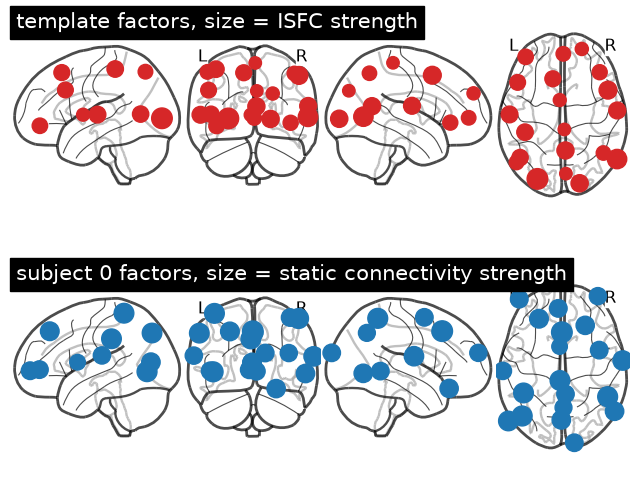

strongest template factors: [12 18  2] strength: [1.59 1.38 1.15]


In [4]:
C = res.isfc()
np.fill_diagonal(C, 0)
strength = np.abs(C).sum(axis=0)
fig, axes = plt.subplots(2, 1, figsize=(8, 6))
plotting.plot_connectome(
    np.zeros_like(C),
    res.global_centers,
    node_size=20 + 200 * strength / strength.max(),
    node_color="tab:red",
    display_mode="lyrz",
    colorbar=False,
    axes=axes[0],
    title="template factors, size = ISFC strength",
)
C0 = res.connectivity(0)
np.fill_diagonal(C0, 0)
s0 = np.abs(C0).sum(axis=0)
plotting.plot_connectome(
    np.zeros_like(C0),
    res.centers[0],
    node_size=20 + 200 * s0 / s0.max(),
    node_color="tab:blue",
    display_mode="lyrz",
    colorbar=False,
    axes=axes[1],
    title="subject 0 factors, size = static connectivity strength",
)
plt.show()
top = np.argsort(strength)[::-1][:3]
print("strongest template factors:", top, "strength:", np.round(strength[top], 2))

## 3. Static connectome, thresholded at 75%

`res.connectivity(s)` is the Pearson correlation between subject `s`'s factor weight time courses (`htfa.static_connectivity`). The subject matrices are averaged in Fisher-z space and drawn with `edge_threshold="75%"`, which keeps the edges whose absolute value is above the 75th percentile.

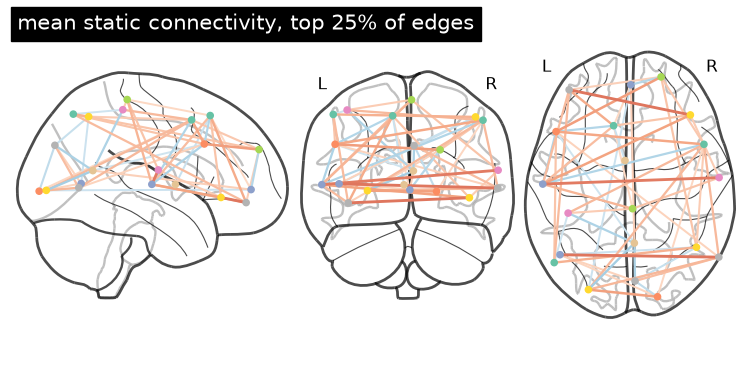

edges: 190; 75th percentile of |r|: 0.205


In [5]:
Z = np.mean(
    [np.arctanh(np.clip(res.connectivity(s), -0.999999, 0.999999)) for s in range(5)],
    axis=0,
)
S = np.tanh(Z)
np.fill_diagonal(S, 0)
plotting.plot_connectome(
    S,
    res.global_centers,
    edge_threshold="75%",
    colorbar=False,
    node_size=20,
    edge_vmin=-1,
    edge_vmax=1,
    title="mean static connectivity, top 25% of edges",
)
plt.show()
upper = S[np.triu_indices_from(S, 1)]
q75 = np.percentile(np.abs(upper), 75)
print(f"edges: {upper.size}; 75th percentile of |r|: {q75:.3f}")

## 4. Sliding-window dynamic connectivity

`res.dynamic_connectivity(s, window)` correlates the factor time courses within each window of `window` samples, giving a `(T - window + 1, K, K)` array. With a 20-sample (40 s) window, the plot shows how the mean absolute connectivity of subject 0 and the correlation of each window's pattern with the static pattern change over the movie.

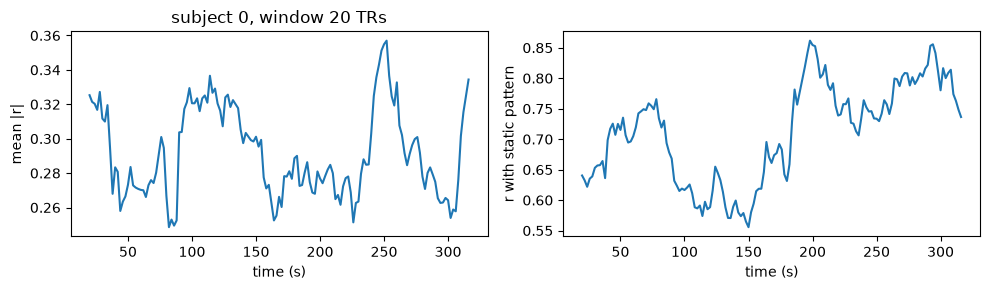

dynamic connectivity shape: (149, 20, 20)
r with static pattern: min 0.56, max 0.86


In [6]:
window = 20
D = res.dynamic_connectivity(0, window=window)
iu = np.triu_indices(D.shape[1], 1)
edges = D[:, iu[0], iu[1]]
static = res.connectivity(0)[iu]
mean_abs = np.abs(edges).mean(axis=1)
similarity = [np.corrcoef(e, static)[0, 1] for e in edges]
t = (np.arange(len(D)) + window / 2) * 2.0  # window centre in seconds (TR = 2 s)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(t, mean_abs)
ax[0].set(xlabel="time (s)", ylabel="mean |r|", title="subject 0, window 20 TRs")
ax[1].plot(t, similarity)
ax[1].set(xlabel="time (s)", ylabel="r with static pattern")
plt.tight_layout()
plt.show()
print("dynamic connectivity shape:", D.shape)
print(f"r with static pattern: min {min(similarity):.2f}, max {max(similarity):.2f}")

## 5. Inter-subject functional correlation (ISFC)

`res.isfc()` correlates each subject's factor time courses with the mean of the other subjects' time courses, symmetrizes, and averages over subjects in Fisher-z space (`htfa.isfc`). Because only stimulus-driven activity is shared between subjects, ISFC discards correlations that arise within one brain only. The template factors make the factor index comparable across subjects. Below, ISFC (left) next to the mean within-subject static connectivity of section 3 (right).

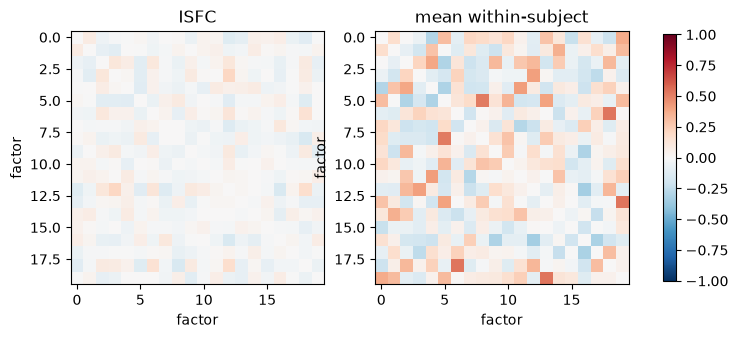

mean |ISFC| 0.046
mean |within-subject r| 0.147
correlation between the two edge patterns: 0.44


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
for a, M, title in ((ax[0], C, "ISFC"), (ax[1], S, "mean within-subject")):
    im = a.imshow(M, vmin=-1, vmax=1, cmap="RdBu_r")
    a.set(title=title, xlabel="factor", ylabel="factor")
fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()
u = np.triu_indices_from(C, 1)
print(f"mean |ISFC| {np.abs(C[u]).mean():.3f}")
print(f"mean |within-subject r| {np.abs(S[u]).mean():.3f}")
print(f"correlation between the two edge patterns: {np.corrcoef(C[u], S[u])[0, 1]:.2f}")

## 6. Animation of sliding-window ISFC

`res.isfc(window=20)` gives one ISFC matrix per window. The animation shows every eighth window as a matrix; it is saved as a GIF in memory and embedded.

windows: 149 | frames: 19
GIF size: 120 kB


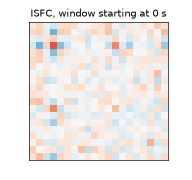

In [8]:
W = res.isfc(window=20)
frames = range(0, len(W), 8)
fig, ax = plt.subplots(figsize=(3.2, 3.0), dpi=60)
im = ax.imshow(W[0], vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks([])
ax.set_yticks([])


def draw(i):
    im.set_data(W[i])
    ax.set_title(f"ISFC, window starting at {2 * i} s")
    return (im,)


anim = FuncAnimation(fig, draw, frames=frames)
path = "isfc_animation.gif"
anim.save(path, writer=PillowWriter(fps=3))
plt.close(fig)
with open(path, "rb") as f:
    gif = f.read()
os.remove(path)
print("windows:", len(W), "| frames:", len(frames))
print(f"GIF size: {len(gif) / 1024:.0f} kB")
Image(data=gif, format="gif")